# Miniproject #3

### Learning goals for this miniproject
1. Understand images as a datatype - be able to inspect and quantify them
2. Learn some methods for automatic cell counting / quantification
3. Learn how to create functions for common analysis tasks
4. Understand how to batch process data for repeated analysis across a dataset

---
### How to use this notebook during class
- Follow along as we go
- Use your **Cards** to indicate where you're at:
    - A **🟩Green card** means you are caught up with Max and **ready to help your classmates**
    - A **🟥Red card** means you are stuck and need help
- <span style='color:red;'>EXERCISE</span> — work on this problem by yourself, or try with a partner if you get stuck
---


First let's import some libraries we will use today. Remember if you don't have a library installed you can pip install it with:

%pip install *package_name*

In [2]:
%pip install scikit-image

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 16.5 MB/s  0:00:00 17.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 17.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-image]0m 4/5 [scikit-image]
Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
from skimage import filters, measure
from skimage.io import imread

## 1) Loading, inspecting, and indexing images

In [45]:
#load in image
filename = 'xy_8bit_mitocheck.tif'
img_cells = imread(filename)
#imgcells = nd array

An image is just an ndarray

In [44]:
print(type(img_cells))
print(img_cells.shape)
#numbers correspond to the rows and columns -> as it is an nd array

<class 'numpy.ndarray'>
(364,)


### <span style='color:red;'>EXERCISE 1</span>: Show the image (5 min)
Use **pyplot** to show the image.
Look it up on Google, stack exchange, or an LLM

In [ ]:
#show the image using pyplot

You can index into an image just like any array. The first dimension is Y (rows of the matrix) and the second is X (columns)

Also note the direction of the y axis when displaying the image

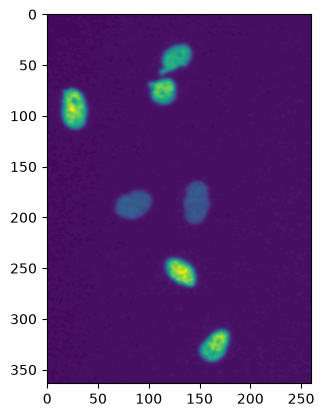

In [10]:
img = plt.imread('xy_8bit_mitocheck.tif')
#not the filename or img_cells -> the actual name of the file in the folder
plt.imshow(img)
#second way to perform this: use stack overflow
#fh, ax = plt.subplots(1, 1, figsize=(4, 4))
#ax.imshow(img_cells, cmap'pink')
#zero at top of y axis-> be aware of the orentation 

### <span style='color:red;'>EXERCISE 2</span>: Inspect image intensity statistics (10 min)
1. Plot a histogram of pixel intensities
2. Compute the **mean** and **median** intensity value of the image


In [32]:
img_cells.flatten().shape

(364,)

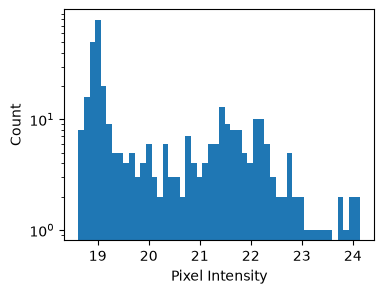

In [35]:
#fh, ax = plt.subplots(1, 1, figsize=(4, 4))
#ax.imshow(img_cells[225:275, 100:150], cmap='grey')
#use as x (94640)
fh, ax = plt.subplots(1, 1, figsize=(4, 3))
ax.hist(img_cells.flatten(), bins=50)
ax.set_xlabel('Pixel Intensity')
ax.set_ylabel('Count')
ax.set_yscale('log')


## 2) Automatic cell detection and quantification

The overall goal here is to automatically detect cells, count them, and compute stats like the size and mean intensity

### Step 1: create a binary mask

The first thing we want to do is create a **binary mask** for the image that identifies individual cells. To do this, let's try a **pseudocode** approach that allows us to not get lost in unfamiliar syntax. Pseudocoding has three steps:
1. Write (as comments) what you want to do and what the result should look like
2. Look up how to implement each command with: Google, documentaion, StackExchange, LLMs*
3. Test your possible solution against your expectation from (1)


*https://microsoft365.com/copilot

skimage has some built in automatic thresholding algorithms - see documentation: https://scikit-image.org/docs/stable/api/skimage.filters.html

### <span style='color:red;'>EXERCISE 3</span>: Try other thresholding algorithms (5 min)
Look at the documentation for different thresholding algorithms that ship with skimage, try them out in the code above and see which work well for this data

https://scikit-image.org/docs/stable/api/skimage.filters.html


33
(364, 260)
[False  True]


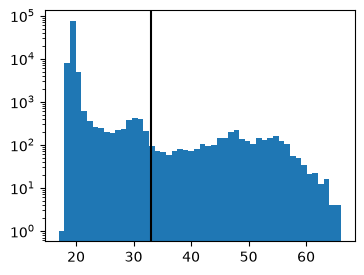

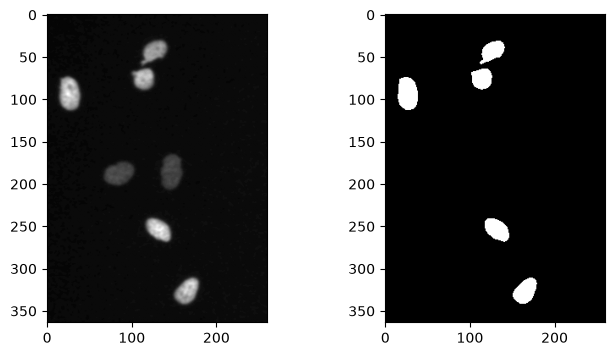

In [46]:
#multiple steps - start with how we will solve this 
#Find a threshold intensity value - value higher than this are included and lower are excluded

thresh = filters.threshold_otsu(img_cells)
print(thresh)

#apply the threshold to return a binary mask
#Mask = ndarray, same size as the image. All the values should True/False

mask = img_cells > thresh
print(mask.shape)
print(np.unique(mask))

#Look at threshold that is computed, compare to the distribution of pixel values
fh, ax = plt.subplots(1, 1, figsize=(4, 3))
ax.hist(img_cells.flatten(), bins=50)
ax.axvline(thresh, color='k')
ax.set_yscale('log')
#View the mask alongside the original image 
fh, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img_cells, cmap='gray')
ax[1].imshow(mask, cmap='gray')


skimage.filters.thresholding.threshold_isodata
skimage.filters.thresholding.threshold_li
skimage.filters.thresholding.threshold_mean
skimage.filters.thresholding.threshold_minimum
skimage.filters.thresholding.threshold_otsu
skimage.filters.thresholding.threshold_triangle
skimage.filters.thresholding.threshold_yen


(<Figure size 800x500 with 8 Axes>,
 array([<Axes: title={'center': 'Original'}>,
        <Axes: title={'center': 'Isodata'}>,
        <Axes: title={'center': 'Li'}>, <Axes: title={'center': 'Mean'}>,
        <Axes: title={'center': 'Minimum'}>,
        <Axes: title={'center': 'Otsu'}>,
        <Axes: title={'center': 'Triangle'}>,
        <Axes: title={'center': 'Yen'}>], dtype=object))

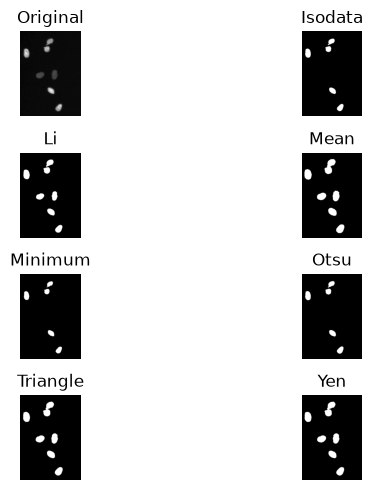

In [47]:
filters.try_all_threshold(img_cells)

### Step 2: label segmented objects in the mask
Scikit image has tools to **label** and measure segmented objects in the image
Documentation: https://scikit-image.org/docs/stable/api/skimage.measure.html#skimage.measure.label

A label image is just an ndarray, the same shape as the input image, with different integers referring to different segmented objects

Let's look at the label image alongside the original image

### Step 3: quantify properties of each cell
We can use the labels image to find the cell's area and mean intensity.

There are at least two ways to do this:
1. **The educational way**: go through each label (except 0) with a **for-loop** and compute the area and intensity using numpy functions
2. **The easy way**: use skimage's built in `regionprops` function: https://scikit-image.org/docs/stable/api/skimage.measure.html#skimage.measure.regionprops

In [ ]:
# The educational way



In [ ]:
# The easy way:


### <span style='color:red;'>EXERCISE 4</span>: Write a cell quantification function  (20 min)
I'm giving you the skeleton of a function definition to take an image as an input and return lists of the mean intensity and area of each detected cell.

Take the relevant lines of code above and modify / arrange them into the body of the function to achieve what you want. Be sure to: check your variable names, only take the bits of code that you need to compute the intensity and area, and test your function afterwards

Let's start together with **pseduocode**


In [ ]:
def measure_cells(input_image):
    """ 
        measure_cells(input_image)
            Using automatic thresholding to identify and quantify cell properties from fluor images
        
        args
            input_image: 2 dimensional ndarray
        returns
            intensity - list
            area - list
    """
    

    return areas, intensities

Let's use our new function

I'm going to go back up to modify our function by adding a quality control check. We want to be able to (optionally) inspect the segmentation to make sure it's behaving correctly for any new image we throw at it

After you modify your function definition remember you have too **re-run** the definition to update it

## 3) Batch processing

Often we write code to repeat some analyis steps on many datafiles. This is called **batch processing**.

Let's use a for-loop, and the function we just defined, to analyze many image files in a row.

We could hard-code in a list of the datafiles we want, or we could use **pattern matching** to identify files in a directory of interest. The Python library for this is built in and it's called **glob**. We can use wildcards like * to match a filename pattern.